In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    auc,
    brier_score_loss
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

In [ ]:
df = pd.read_excel("DATA_CLEAN.xlsx")

# Drop >90% missing columns
df = df.loc[:, df.isnull().mean() < 0.9]

df["Severity"] = (
    df["Severity"]
    .map({
        "complicated": 1,
        "uncomplicated": 0
    })
)

X = df.drop(columns=['Diagnosis', 'Severity'])
y = df['Severity']

In [ ]:
print(y.value_counts())

Severity
0    660
1    119
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [ ]:
num_cols = X_train.select_dtypes(include=['int64','float64']).columns
cat_cols = X_train.select_dtypes(include=['object','category']).columns

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

In [ ]:
pipeline = ImbPipeline([
    ('preprocessing', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
param_dist = {
    'classifier__n_estimators': [100, 150, 200],  # more trees = stability
    'classifier__learning_rate': [0.01, 0.03, 0.05],  # lower LR works better with imbalance
    'classifier__max_depth': [2, 3, 4],  # avoid too shallow (2) and too deep
    'classifier__subsample': [0.5, 0.6, 0.7],
    'classifier__colsample_bytree': [0.5, 0.6, 0.7],

    # 🔥 MOST IMPORTANT FOR IMBALANCE
    'classifier__scale_pos_weight': [4, 5, 6],

    # Optional regularization (recommended)
    'classifier__gamma': [0, 0.5, 1],
    'classifier__min_child_weight': [1, 3, 5]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=40,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

search.fit(X_train, y_train)

best_model = search.best_estimator_

print("Best Parameters:", search.best_params_)
print("Best CV ROC-AUC:", search.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters: {'classifier__subsample': 0.7, 'classifier__scale_pos_weight': 4, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 5, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.05, 'classifier__gamma': 0, 'classifier__colsample_bytree': 0.6}
Best CV ROC-AUC: 0.9009968317018963


In [ ]:
y_pred_t = best_model.predict(X_train)
y_proba_t = best_model.predict_proba(X_train)[:,1]

print("Train ROC-AUC:", roc_auc_score(y_train, y_proba_t))
print("PR-AUC:", average_precision_score(y_train, y_proba_t))
print("Brier Score:", brier_score_loss(y_train, y_proba_t))

print("\nClassification Report:\n")
print(classification_report(y_train, y_pred_t))

Train ROC-AUC: 0.9719696969696969
PR-AUC: 0.8493236469685446
Brier Score: 0.07496092721463635

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.88      0.93       528
           1       0.60      0.96      0.74        95

    accuracy                           0.90       623
   macro avg       0.80      0.92      0.84       623
weighted avg       0.93      0.90      0.90       623



In [ ]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:,1]

print("Test ROC-AUC:", roc_auc_score(y_test, y_proba))
print("PR-AUC:", average_precision_score(y_test, y_proba))
print("Brier Score:", brier_score_loss(y_test, y_proba))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Test ROC-AUC: 0.9245580808080808
PR-AUC: 0.7367418807872519
Brier Score: 0.0918502695226092

Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.86      0.91       132
           1       0.51      0.79      0.62        24

    accuracy                           0.85       156
   macro avg       0.74      0.83      0.77       156
weighted avg       0.89      0.85      0.86       156



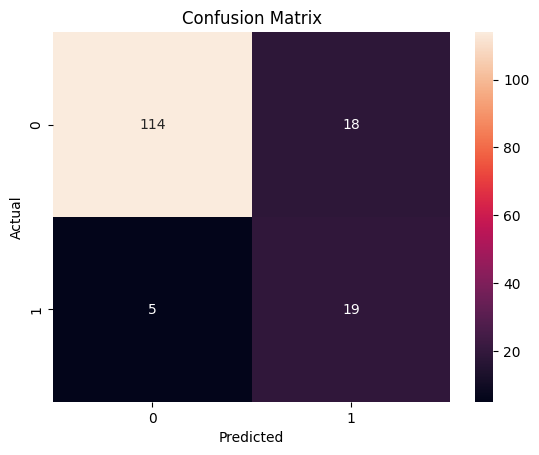

In [ ]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

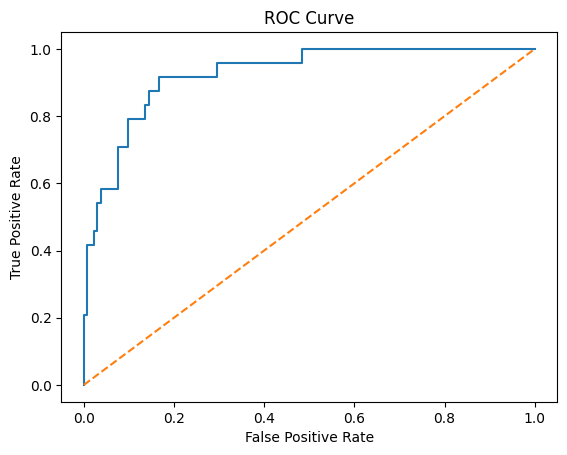

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

Test AUPR: 0.7311815831848862


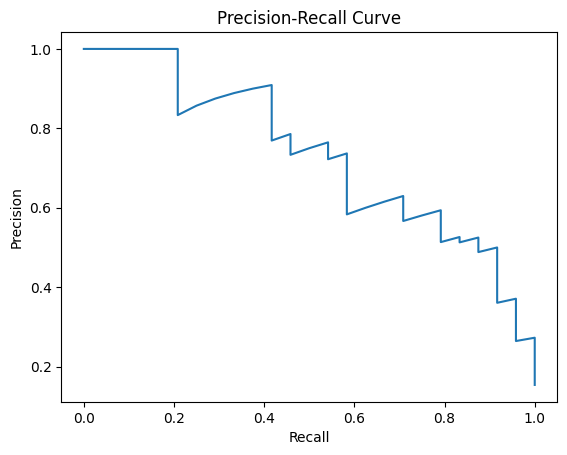

In [ ]:
precision, recall, _ = precision_recall_curve(y_test, y_proba)

aupr_train = auc(recall, precision)
print("Test AUPR:", aupr_train)

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

In [ ]:
import shap

X_test_processed = best_model.named_steps['preprocessing'].transform(X_test)
xgb_model = best_model.named_steps['classifier']

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_processed)

feature_names = best_model.named_steps['preprocessing'].get_feature_names_out()

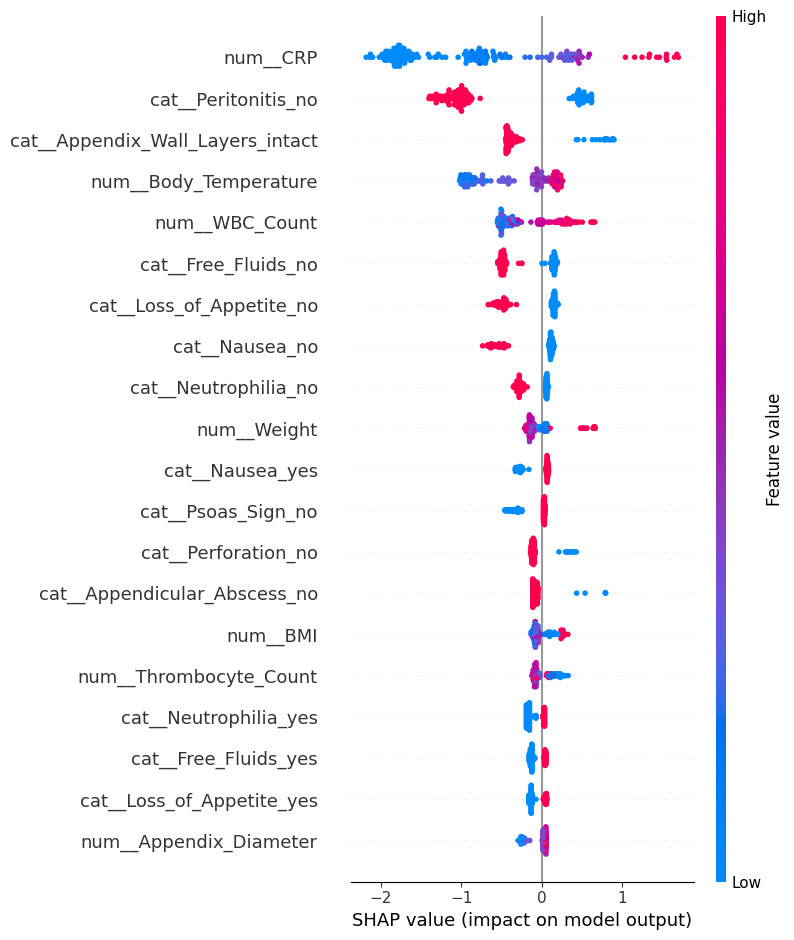

In [ ]:
shap.summary_plot(shap_values, X_test_processed, feature_names=feature_names)

In [ ]:
shap_importance = np.abs(shap_values).mean(axis=0)

shap_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_SHAP": shap_importance
}).sort_values(by="Mean_SHAP", ascending=False)

shap_df.head(15)

,Feature,Mean_SHAP
14,num__CRP,1.162291
51,cat__Peritonitis_no,0.913088
58,cat__Appendix_Wall_Layers_intact,0.433621
7,num__Body_Temperature,0.423011
8,num__WBC_Count,0.367188
56,cat__Free_Fluids_no,0.344388
27,cat__Loss_of_Appetite_no,0.318489
25,cat__Nausea_no,0.276864
29,cat__Neutrophilia_no,0.175775
3,num__Weight,0.146643


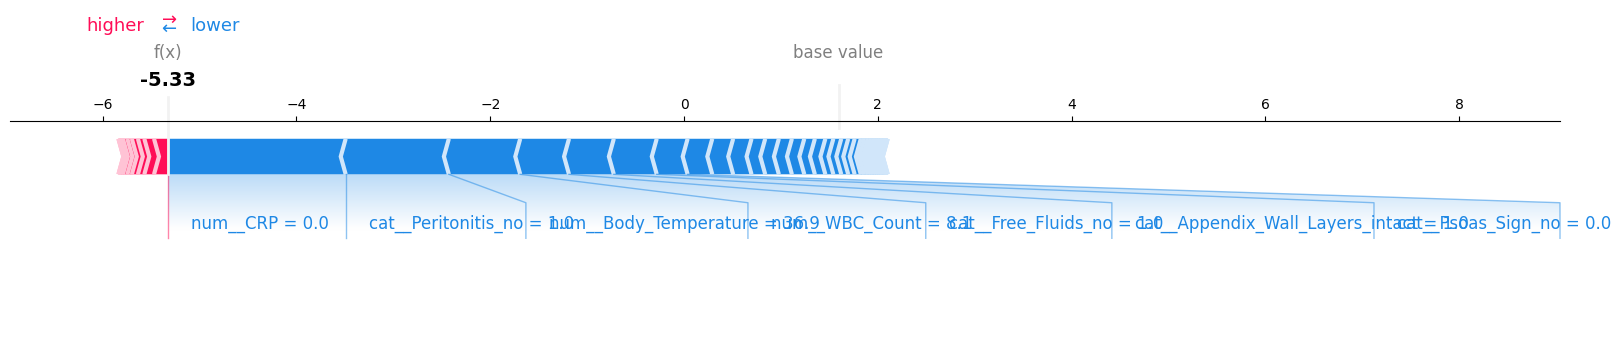

In [ ]:
shap.force_plot(
    explainer.expected_value,
    shap_values[0],
    X_test_processed[0],
    feature_names=feature_names,
    matplotlib=True
)

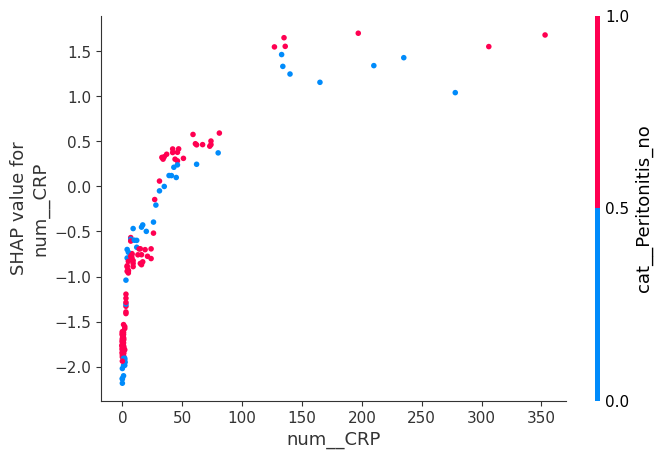

In [ ]:
shap.dependence_plot(
    shap_df.iloc[0]["Feature"],
    shap_values,
    X_test_processed,
    feature_names=feature_names
)

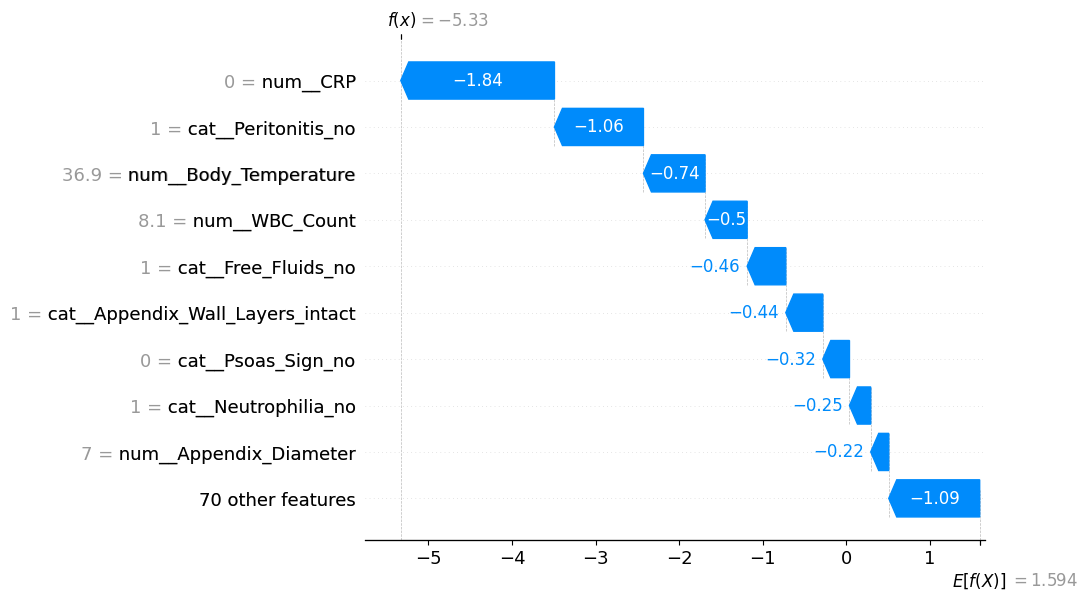

In [ ]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_test_processed[0],
        feature_names=feature_names
    )
)

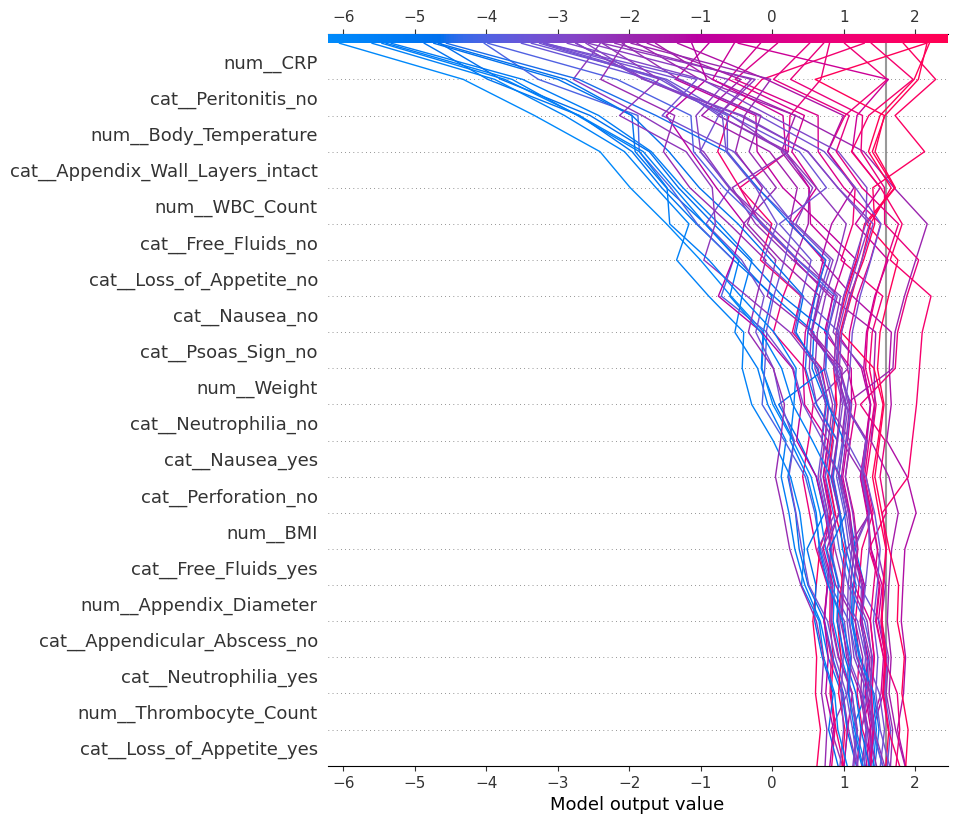

In [ ]:
shap.decision_plot(
    explainer.expected_value,
    shap_values[:50],
    feature_names=feature_names
)

In [ ]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_validate

# Custom scoring functions for sensitivity and specificity
def sensitivity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() # Unpack 2x2 confusion matrix elements
    return tp / (tp + fn) if (tp + fn) != 0 else 0.0

def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() # Unpack 2x2 confusion matrix elements
    return tn / (tn + fp) if (tn + fp) != 0 else 0.0

# Create scorers
sens_scorer = make_scorer(sensitivity_score)
spec_scorer = make_scorer(specificity_score)

# Perform cross-validation with the best_model on X_train, y_train
# We reuse the 'cv' object (StratifiedKFold) defined during RandomizedSearchCV
cv_results_metrics = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=cv, # Using the 'cv' variable from RandomizedSearchCV
    scoring={'sensitivity': sens_scorer, 'specificity': spec_scorer},
    return_train_score=False, # Focus on test scores for evaluation
    n_jobs=-1 # Use all available cores
)

# Extract scores from cross-validation results
sensitivities = cv_results_metrics['test_sensitivity']
specificities = cv_results_metrics['test_specificity']

# Calculate mean and standard deviation
mean_sens = np.mean(sensitivities)
std_sens = np.std(sensitivities)
mean_spec = np.mean(specificities)
std_spec = np.std(specificities)

print(f"Average Sensitivity (across CV folds): {mean_sens:.4f} (Std: {std_sens:.4f})")
print(f"Average Specificity (across CV folds): {mean_spec:.4f} (Std: {std_spec:.4f})")

Average Sensitivity (across CV folds): 0.7579 (Std: 0.0537)
Average Specificity (across CV folds): 0.8655 (Std: 0.0380)


In [ ]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_validate

# Custom scoring functions for Positive Predictive Value (PPV) and Negative Predictive Value (NPV)
def ppv_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() # Unpack 2x2 confusion matrix elements
    return tp / (tp + fp) if (tp + fp) != 0 else 0.0

def npv_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() # Unpack 2x2 confusion matrix elements
    return tn / (tn + fn) if (tn + fn) != 0 else 0.0

# Create scorers
ppv_scorer = make_scorer(ppv_score)
npv_scorer = make_scorer(npv_score)

# Perform cross-validation with the best_model on X_train, y_train
# We reuse the 'cv' object (StratifiedKFold) defined during RandomizedSearchCV
cv_results_ppv_npv = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=cv, # Using the 'cv' variable from RandomizedSearchCV
    scoring={'ppv': ppv_scorer, 'npv': npv_scorer},
    return_train_score=False, # Focus on test scores for evaluation
    n_jobs=-1 # Use all available cores
)

# Extract scores from cross-validation results
ppvs = cv_results_ppv_npv['test_ppv']
npvs = cv_results_ppv_npv['test_npv']

# Calculate mean and standard deviation
mean_ppv = np.mean(ppvs)
std_ppv = np.std(ppvs)
mean_npv = np.mean(npvs)
std_npv = np.std(npvs)

print(f"Average PPV (across CV folds): {mean_ppv:.4f} (Std: {std_ppv:.4f})")
print(f"Average NPV (across CV folds): {mean_npv:.4f} (Std: {std_npv:.4f})")

Average PPV (across CV folds): 0.5126 (Std: 0.0793)
Average NPV (across CV folds): 0.9518 (Std: 0.0116)


In [ ]:
# ==============================
# METRIC CALCULATION FUNCTION
# ==============================

def calculate_metrics(y_true, y_prob, threshold=0.5):

    # Convert probabilities to binary predictions
    y_pred = (y_prob >= threshold).astype(int)

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    # Metrics
    sensitivity = tp / (tp + fn) if (tp + fn) != 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) != 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) != 0 else 0
    npv = tn / (tn + fn) if (tn + fn) != 0 else 0

    roc_auc = roc_auc_score(y_true, y_prob)
    aupr = average_precision_score(y_true, y_prob)
    brier = brier_score_loss(y_true, y_prob)

    metrics = {
        "ROC-AUC": roc_auc,
        "AUPR": aupr,
        "Brier Score": brier,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "PPV": ppv,
        "NPV": npv,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    }

    return metrics


In [ ]:
# ==============================
# MAIN MODEL EVALUATION FUNCTION
# ==============================

def evaluate_model(model, X_train, y_train, X_test, y_test):

    # Probabilities
    train_probs = model.predict_proba(X_train)[:,1]
    test_probs = model.predict_proba(X_test)[:,1]

    # Metrics
    train_metrics = calculate_metrics(y_train, train_probs)
    test_metrics = calculate_metrics(y_test, test_probs)

    # Convert to DataFrame
    results = pd.DataFrame([train_metrics, test_metrics],
                           index=["Train", "Test"])

    print("\n============================")
    print("MODEL PERFORMANCE SUMMARY")
    print("============================\n")

    print(results)

    # Confusion Matrix Display
    train_pred = (train_probs >= 0.5).astype(int)
    test_pred = (test_probs >= 0.5).astype(int)

    print("\nTrain Confusion Matrix")
    print(confusion_matrix(y_train, train_pred))

    print("\nTest Confusion Matrix")
    print(confusion_matrix(y_test, test_pred))

    print("\nClassification Report (Train)")
    print(classification_report(y_train, train_pred))

    print("\nClassification Report (Test)")
    print(classification_report(y_test, test_pred))


    # ==============================
    # ROC CURVE
    # ==============================

    fpr_train, tpr_train, _ = roc_curve(y_train, train_probs)
    fpr_test, tpr_test, _ = roc_curve(y_test, test_probs)

    plt.figure()
    plt.plot(fpr_train, tpr_train, label="Train ROC")
    plt.plot(fpr_test, tpr_test, label="Test ROC")
    plt.plot([0,1],[0,1],'--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()

    # ==============================
    # PRECISION-RECALL CURVE
    # ==============================

    prec_train, rec_train, _ = precision_recall_curve(y_train, train_probs)
    prec_test, rec_test, _ = precision_recall_curve(y_test, test_probs)

    plt.figure()
    plt.plot(rec_train, prec_train, label="Train PR")
    plt.plot(rec_test, prec_test, label="Test PR")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve")
    plt.legend()
    plt.show()

    return results


# ==============================
# USAGE EXAMPLE
# ==============================

# Example usage with any trained model

# results = evaluate_model(model, X_train, y_train, X_test, y_test)

# Example:
# results = evaluate_model(stacking_model, X_train, y_train, X_test, y_test)



MODEL PERFORMANCE SUMMARY

        ROC-AUC      AUPR  Brier Score  Sensitivity  Specificity       PPV  \
Train  0.971970  0.849324     0.074961     0.957895     0.884470  0.598684   
Test   0.924558  0.736742     0.091850     0.791667     0.863636  0.513514   

            NPV  TP  FP   TN  FN  
Train  0.991507  91  61  467   4  
Test   0.957983  19  18  114   5  

Train Confusion Matrix
[[467  61]
 [  4  91]]

Test Confusion Matrix
[[114  18]
 [  5  19]]

Classification Report (Train)
              precision    recall  f1-score   support

           0       0.99      0.88      0.93       528
           1       0.60      0.96      0.74        95

    accuracy                           0.90       623
   macro avg       0.80      0.92      0.84       623
weighted avg       0.93      0.90      0.90       623


Classification Report (Test)
              precision    recall  f1-score   support

           0       0.96      0.86      0.91       132
           1       0.51      0.79      0.6

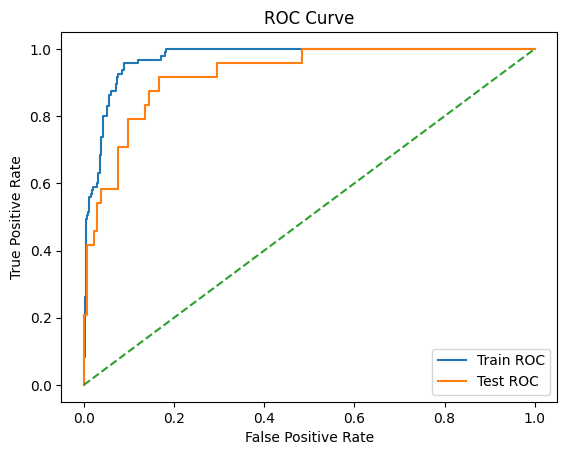

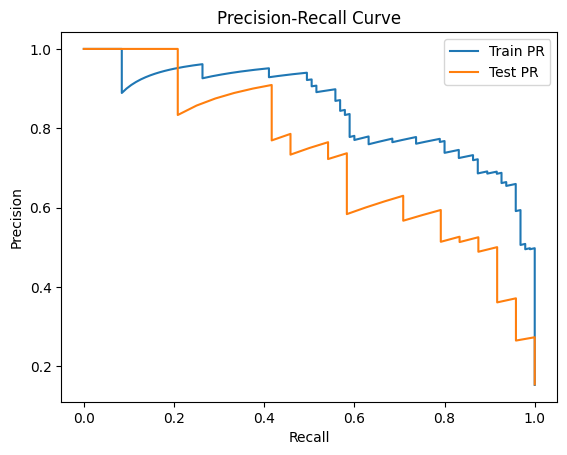

In [ ]:
results = evaluate_model(best_model, X_train, y_train, X_test, y_test)